In [28]:

input = {
"EXT_SOURCE_1":0.5,
"EXT_SOURCE_3":0.5,
"EXT_SOURCE_WEIGHTED":0.5,
"AMT_CREDIT":500000,
"AMT_GOODS_PRICE":450000,
"GOODS_CREDIT_RATIO":0.9,
"YEARS_AGE":35,
"NAME_FAMILY_STATUS":"Married",
"FLAG_DOCUMENT_3":1,
"YEARS_EMPLOYED":5,
"NAME_INCOME_TYPE":"Working",
"IP_WORST_DPD_720D":0,
"B_DEBT_TO_CREDIT_RATIO":0.2,
"B_NUM_ACTIVE_CREDIT_720D":0,
"B_CREDIT_DURATION_MIN":180,
"IP_RATIO_LATE_PAYMENTS_2160D":0,
"IP_NUM_COMPLETED_LOANS":2,
"CB_WT_CREDIT_UTIL_TREND_3M_12M":0,
"CB_AVG_ATM_WITHDRAWAL_FREQ_6M":1,
"REGION_RATING_CLIENT_W_CITY":2,
"PA_RATIO_APPROVED_LOANS":0.5,
"PA_AVG_AMT_ANNUITY_POS":10000,
"PA_AVG_RISK_WEIGHT_1080D":2,
"PA_RATIO_CREDIT_APPLICATION_Cash":0,
"PA_RATIO_CREDIT_APPLICATION_POS":0,
"OCCUPATION_GROUP":"SKILLED_PRO",
"ORG_GROUP":"ORG_PRIVATE",
"NAME_EDUCATION_TYPE":"Higher education",
"CODE_GENDER":"M",
}

In [36]:
import numpy as np
np.array(input.values())

array(dict_values([0.5, 0.5, 0.5, 500000, 450000, 0.9, 35, 'Married', 1, 5, 'Working', 0, 0.2, 0, 180, 0, 2, 0, 1, 2, 0.5, 10000, 2, 0, 0, 'SKILLED_PRO', 'ORG_PRIVATE', 'Higher education', 'M']),
      dtype=object)

# MODEL 

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

def auc_gini_ks(y_true, y_pred_prob):
    """
    Calculate AUC, Gini, and KS statistic for credit risk models.

    Parameters:
    y_true : array-like, true binary labels (0 = good, 1 = bad)
    y_pred_prob : array-like, predicted probabilities of default (1 = bad)

    Returns:
    dict with keys: 'AUC', 'Gini', 'KS'
    """
    # AUC
    auc = roc_auc_score(y_true, y_pred_prob)
    
    # Gini coefficient
    gini = 2 * auc - 1
    
    # KS statistic
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)
    ks = max(tpr - fpr)
    
    print("AUC", auc)
    print("Gini", gini)
    print("KS", ks)


In [2]:
X_train = pd.read_csv(r'D:\home loan credit risk\artifact\data\final\X_train_final.csv')
X_test = pd.read_csv(r'D:\home loan credit risk\artifact\data\final\X_test_final.csv')

y_train = pd.read_csv(r'D:\home loan credit risk\artifact\data\data_splits\y_train.csv')
y_test = pd.read_csv(r'D:\home loan credit risk\artifact\data\data_splits\y_test.csv')

In [3]:
final_selected_features = ['EXT_SOURCE_WEIGHTED',
 'ANNUITY_CREDIT_RATIO',
 'YEARS_EMPLOYED',
 'AMT_GOODS_PRICE',
 'IP_WORST_DPD_720D',
 'GOODS_CREDIT_RATIO',
 'IP_RATIO_LATE_PAYMENTS_2160D',
 'B_NUM_ACTIVE_CREDIT_720D',
 'ORG_GROUP',
 'REGION_RATING_CLIENT_W_CITY',
 'NAME_EDUCATION_TYPE',
 'PA_RATIO_CREDIT_APPLICATION_Cash',
 'PA_RATIO_CREDIT_APPLICATION_POS',
 'CODE_GENDER',
 'PA_AVG_AMT_ANNUITY_POS',
 'EXT_SOURCE_3',
 'EXT_SOURCE_1',
 'B_DEBT_TO_CREDIT_RATIO',
 'PA_RATIO_APPROVED_LOANS',
 'IP_NUM_COMPLETED_LOANS',
 'PA_AVG_RISK_WEIGHT_1080D',
 'OCCUPATION_GROUP',
 'B_CREDIT_DURATION_MIN',
 'CB_AVG_ATM_WITHDRAWAL_FREQ_6M',
 'CB_WT_CREDIT_UTIL_TREND_3M_12M',
 'YEARS_AGE',
 'NAME_FAMILY_STATUS',
 'AMT_CREDIT',
 'FLAG_DOCUMENT_3',
 'NAME_INCOME_TYPE']

In [4]:
len(final_selected_features)

30

In [5]:
from src.utils.main_utils import downcast_df_variables

X_train = downcast_df_variables(X_train)
X_test = downcast_df_variables(X_test)

X_train = X_train[final_selected_features].copy()
X_test = X_test[final_selected_features].copy()


y_train = y_train.values.ravel()
y_test = y_test.values.ravel()

In [7]:
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
import numpy as np

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    
    # C value search space
    C = trial.suggest_float('C', 0.001, 10.0, log=True)
    
    # Class weight options based on 8:92 imbalance
    weight_options = {
        'balanced'  : 'balanced',
        'ratio_5'   : {0: 1, 1: 5},
        'ratio_8'   : {0: 1, 1: 8},    # exact imbalance ratio
        'ratio_10'  : {0: 1, 1: 10},
        'ratio_12'  : {0: 1, 1: 12},
        'ratio_15'  : {0: 1, 1: 15},
    }
    
    weight_name = trial.suggest_categorical(
        'class_weight', 
        list(weight_options.keys())
    )
    class_weight = weight_options[weight_name]
    
    model = LogisticRegression(
        penalty      = 'l2',
        solver       = 'liblinear',
        C            = C,
        class_weight = class_weight,
        max_iter     = 2000,
        random_state = 42
    )
    
    # Stratified KFold — keeps 8:92 ratio in each fold
    cv     = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(
        model, 
        X_train, 
        y_train,
        cv      = cv,
        scoring = 'roc_auc',
        n_jobs  = -1
    )
    
    return scores.mean()


# Run optimization
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

# Best results
print("=" * 40)
print(f"Best AUC        : {study.best_value:.4f}")
print(f"Best C          : {study.best_params['C']:.4f}")
print(f"Best Weight     : {study.best_params['class_weight']}")
print("=" * 40)

  0%|          | 0/100 [00:00<?, ?it/s]

Best AUC        : 0.7655
Best C          : 0.0540
Best Weight     : ratio_8


C:\Users\bhosa\AppData\Local\Temp\ipykernel_14560\4031892500.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

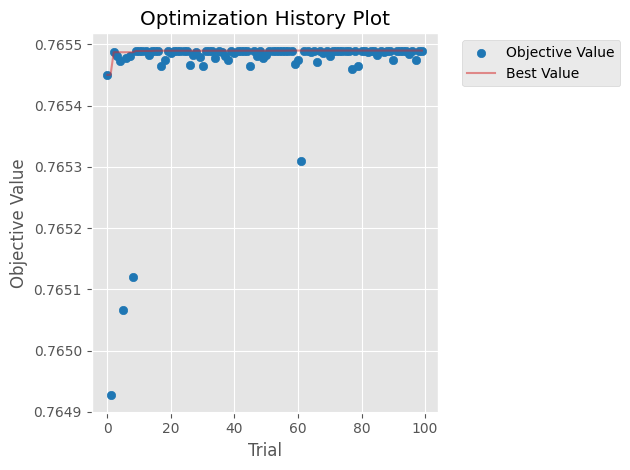

In [8]:
# See how optuna searched
optuna.visualization.matplotlib.plot_optimization_history(study)

C:\Users\bhosa\AppData\Local\Temp\ipykernel_14560\82623574.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

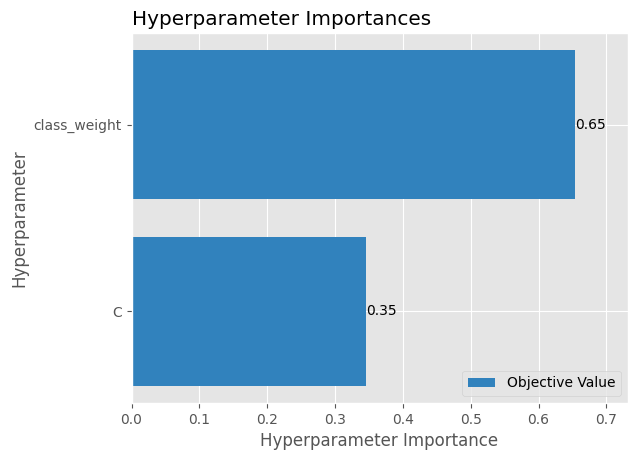

In [9]:
optuna.visualization.matplotlib.plot_param_importances(study)


In [ ]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold

rfe = RFECV(
    estimator = LogisticRegression(
        penalty      = 'l2',
        solver       = 'liblinear',
        C            = 0.054,
        class_weight = {0:1, 1:8},
        max_iter     = 2000,
        random_state = 42
    ),
    step       = 1,
    cv         = StratifiedKFold(5, shuffle=True, random_state=42),
    scoring    = 'roc_auc',
    min_features_to_select = 15,  # don't go below 15
    n_jobs     = -1
)
rfe.fit(X_train, y_train)

# What RFECV kept
kept     = X_train.columns[rfe.support_].tolist()
removed  = X_train.columns[~rfe.support_].tolist()

print(f"Optimal features : {rfe.n_features_}")
print(f"\nKept    : {kept}")
print(f"\nRemoved : {removed}")

Optimal features : 30

Kept    : ['EXT_SOURCE_WEIGHTED', 'ANNUITY_CREDIT_RATIO', 'YEARS_EMPLOYED', 'AMT_GOODS_PRICE', 'IP_WORST_DPD_720D', 'GOODS_CREDIT_RATIO', 'IP_RATIO_LATE_PAYMENTS_2160D', 'B_NUM_ACTIVE_CREDIT_720D', 'ORG_GROUP', 'REGION_RATING_CLIENT_W_CITY', 'NAME_EDUCATION_TYPE', 'PA_RATIO_CREDIT_APPLICATION_Cash', 'PA_RATIO_CREDIT_APPLICATION_POS', 'CODE_GENDER', 'PA_AVG_AMT_ANNUITY_POS', 'EXT_SOURCE_3', 'EXT_SOURCE_1', 'B_DEBT_TO_CREDIT_RATIO', 'PA_RATIO_APPROVED_LOANS', 'IP_NUM_COMPLETED_LOANS', 'PA_AVG_RISK_WEIGHT_1080D', 'OCCUPATION_GROUP', 'B_CREDIT_DURATION_MIN', 'CB_AVG_ATM_WITHDRAWAL_FREQ_6M', 'CB_WT_CREDIT_UTIL_TREND_3M_12M', 'YEARS_AGE', 'NAME_FAMILY_STATUS', 'AMT_CREDIT', 'FLAG_DOCUMENT_3', 'NAME_INCOME_TYPE']

Removed : []


In [6]:
# SELECTEF THE C VALUE AND RETRAIN
from sklearn.linear_model import LogisticRegression

final_model = LogisticRegression(
        penalty='l2',          # removes weak features
        solver='liblinear',    # required for L1
        C=1,                 # strong regularization
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    )
final_model.fit(X_train,y_train)
train_prob = final_model.predict_proba(X_train)
train_prob = train_prob[:,1]

test_prob = final_model.predict_proba(X_test)
test_prob = test_prob[:,1]

In [7]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(
        final_model, 
        method='sigmoid',
        cv='prefit'
    )

calibrated_model.fit(X_train, y_train) 

# validation log
raw_pd        = final_model.predict_proba(X_train)[:, 1]
calibrated_pd = calibrated_model.predict_proba(X_train)[:, 1]


c:\ProgramData\anaconda3\envs\homecredit\Lib\site-packages\sklearn\calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


In [11]:
calibrated_pd

array([0.05044736, 0.10112568, 0.0670027 , ..., 0.01609566, 0.03926745,
       0.04872704], shape=(246008,))

In [9]:
raw_pd

array([0.37537951, 0.56187157, 0.44899603, ..., 0.15457071, 0.31558572,
       0.36677269], shape=(246008,))

In [8]:
auc_gini_ks(y_train,calibrated_pd)

AUC 0.7658991858587522
Gini 0.5317983717175043
KS 0.3980608488864719


In [33]:
auc_gini_ks(y_train,train_prob)

AUC 0.7658960417796964
Gini 0.5317920835593928
KS 0.3979110659488272


In [34]:
auc_gini_ks(y_test,test_prob)

AUC 0.7663764929624995
Gini 0.5327529859249991
KS 0.40266870748321126


In [35]:
feature_importance = pd.DataFrame({
    'feature': final_model.feature_names_in_,
    'coeff': final_model.coef_[0]  
})
feature_importance = feature_importance.reset_index(drop=True)

In [36]:
feature_importance

,feature,coeff
0,EXT_SOURCE_WEIGHTED,-0.667019
1,ANNUITY_CREDIT_RATIO,-0.395095
2,YEARS_EMPLOYED,-0.413912
3,AMT_GOODS_PRICE,-0.465601
4,IP_WORST_DPD_720D,-0.385682
5,GOODS_CREDIT_RATIO,-0.442453
6,IP_RATIO_LATE_PAYMENTS_2160D,-0.461406
7,B_NUM_ACTIVE_CREDIT_720D,-0.403033
8,ORG_GROUP,-0.408463
9,REGION_RATING_CLIENT_W_CITY,-0.387212


# DIAGRAMS LATER

AUC Score: 0.7664


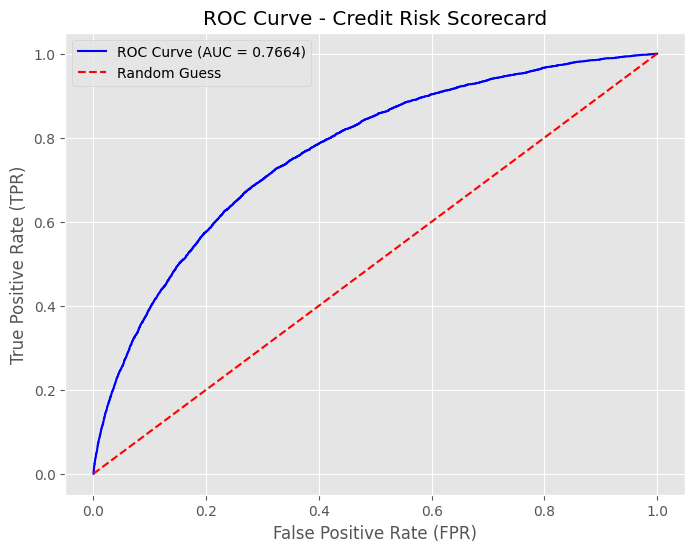

In [37]:
# Import required libraries
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score


# Compute AUC
auc_score = roc_auc_score(y_test, test_prob)
print(f"AUC Score: {auc_score:.4f}")

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test,test_prob)

# Plot ROC curve
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0,1], [0,1], color='red', linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve - Credit Risk Scorecard')
plt.legend()
plt.grid(True)
plt.show()

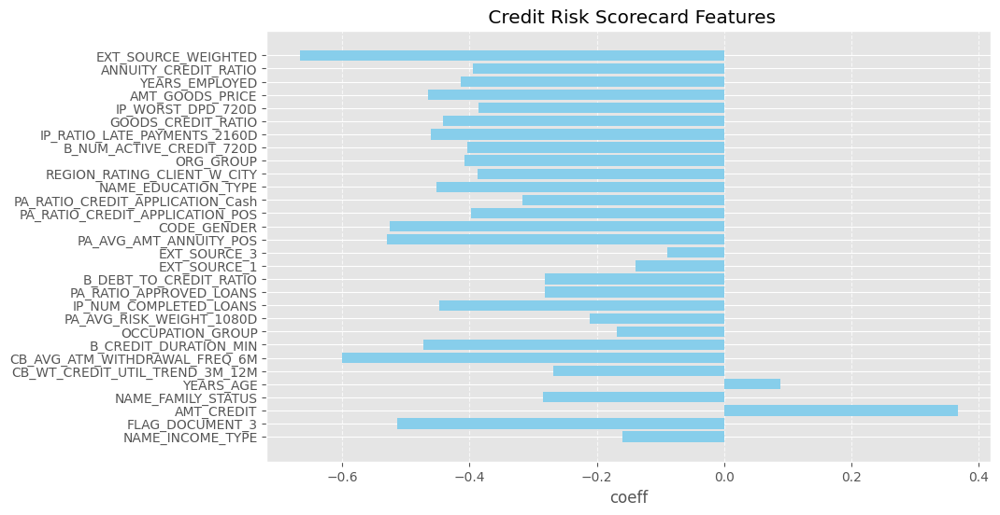

In [38]:
# Plot top 10 features
plt.figure(figsize=(10,6))
plt.barh(feature_importance["feature"][::-1], feature_importance["coeff"][::-1], color='skyblue')
plt.xlabel("coeff")
plt.title(" Credit Risk Scorecard Features")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [39]:
import numpy as np
import plotly.graph_objects as go
from sklearn.metrics import precision_recall_curve


# Step 2: Compute precision, recall, thresholds
precision, recall, thresholds = precision_recall_curve(
    y_train,
    train_prob
)

# Match lengths
precision = precision[:-1]
recall = recall[:-1]

# Step 3: Interactive plot
fig = go.Figure()

# Precision line
fig.add_trace(
    go.Scatter(
        x=thresholds,
        y=precision,
        mode='lines',
        name='Precision'
    )
)

# Recall line
fig.add_trace(
    go.Scatter(
        x=thresholds,
        y=recall,
        mode='lines',
        name='Recall'
    )
)

fig.update_layout(
    title='Interactive Precision-Recall vs Threshold',
    xaxis_title='Threshold',
    yaxis_title='Score',
    hovermode='x unified'
)

fig.show()

# SCORECARD

## 1) Feature score rules

In [13]:
iv_df = pd.read_csv(r'D:\home loan credit risk\artifact\binning\prebin\iv_df.csv')


In [14]:
from src.constants.artifacts_paths import *
import numpy as np

BASE_SCORE = 600
BASE_ODDS = 50
PDO = 25
#changes with model intercept
intercept = final_model.intercept_ [0]

FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE + FACTOR * np.log(BASE_ODDS)
INTERCEPT_POINTS = OFFSET - FACTOR * intercept


In [15]:
INTERCEPT_POINTS

np.float64(749.8053802166745)

In [24]:
from src.constants.artifacts_paths import *
import numpy as np

BASE_SCORE = 600
BASE_ODDS = 50
PDO = 25
#changes with model intercept
intercept = final_model.intercept_ [0]

FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE + FACTOR * np.log(BASE_ODDS)
INTERCEPT_POINTS = OFFSET - FACTOR * intercept


from src.entity.artifact_entity import FeatureBinMergingArtifact
import pickle
import gc


def numerical_score_rules(num_bins, final_selected_features, iv_df, feature_importance, FACTOR):

    final_summary = {}

    for feature, summary_data in num_bins.items():
        if feature not in final_selected_features:
            continue

        feature_iv   = iv_df[iv_df['feature'] == feature]['IV'].values[0]
        feature_coef = feature_importance[feature_importance['feature'] == feature]['coeff'].values[0]

        summary_data['Feature IV'] = feature_iv

        df = summary_data[['feature', 'Bin', 'WoE', 'Event rate', 'Count (%)', 'Feature IV']].copy()

        df['feature_coeff_model'] = feature_coef
        df['score_points']        = 0.0

        n_bin = df['Bin'].iloc[:-1].shape[0]

        for bin_no in range(n_bin):
            idx       = df.index[bin_no]
            bin_score = (df.loc[idx, 'WoE'] * feature_coef) * (-FACTOR) 
            df.loc[idx, 'score_points'] = bin_score

        final_summary[feature] = df

    final_scorecard_rules = pd.concat(final_summary.values(), ignore_index=True)

    return final_scorecard_rules


# ── Load Dependencies ─────────────────────────────────────────────────────────
import pickle

with open('D:/home loan credit risk/artifact/data/final/selected_num_bins.pkl', 'rb') as f:
    num_bins = pickle.load(f)
# ── Call numerical_score_rules ────────────────────────────────────────────────
num_scorecard = numerical_score_rules(
    num_bins               = num_bins,
    final_selected_features = final_selected_features,
    iv_df                  = iv_df,
    feature_importance     = feature_importance,
    FACTOR                 = FACTOR
)

del num_bins
gc.collect()

print(num_scorecard.shape)
num_scorecard.head(20)

(149, 8)


,feature,Bin,WoE,Event rate,Count (%),Feature IV,feature_coeff_model,score_points
0,AMT_GOODS_PRICE,"(40499.999, 450000.0]",-0.172289,0.094474,0.513138,0.102669,-0.475736,-2.956228
1,AMT_GOODS_PRICE,"(450000.0, 675000.0]",0.047508,0.077273,0.224359,0.102669,-0.475736,0.815168
2,AMT_GOODS_PRICE,"(675000.0, 900000.0]",0.269344,0.062866,0.125053,0.102669,-0.475736,4.621550
3,AMT_GOODS_PRICE,"(900000.0, 4050000.0]",0.488179,0.051142,0.136552,0.102669,-0.475736,8.376440
4,AMT_GOODS_PRICE,SPECIAL_-99999,0.052425,0.076923,0.000898,0.102669,-0.475736,0.899531
5,AMT_GOODS_PRICE,None,NaN,0.080729,1.000000,0.102669,-0.475736,0.000000
6,REGION_RATING_CLIENT_W_CITY,1,0.540166,0.048677,0.111065,0.051572,-0.431101,8.398870
7,REGION_RATING_CLIENT_W_CITY,2,0.023166,0.079026,0.746407,0.051572,-0.431101,0.360206
8,REGION_RATING_CLIENT_W_CITY,3,-0.388110,0.114622,0.142528,0.051572,-0.431101,-6.034589
9,REGION_RATING_CLIENT_W_CITY,None,NaN,0.080729,1.000000,0.051572,-0.431101,0.000000


In [25]:
def categorical_score_rules(cat_bin_df, final_selected_features, iv_df, feature_importance, FACTOR):

    cat_bin_df   = cat_bin_df.rename(columns={'Count(%)': 'Count (%)'})
    cat_features = cat_bin_df['feature'].unique().tolist()
    results      = []

    for feature in final_selected_features:
        if feature not in cat_features:
            continue

        feature_coef = feature_importance[feature_importance['feature'] == feature]['coeff'].values[0]
        feature_iv   = iv_df[iv_df['feature'] == feature]['IV'].values[0]

        temp = cat_bin_df[cat_bin_df['feature'] == feature][['feature', 'Bin', 'WoE', 'Event rate', 'Count (%)', 'rare_categories']].copy()

        temp['Feature IV']          = feature_iv
        temp['feature_coeff_model'] = feature_coef
        temp['score_points']        = (temp['WoE'] * feature_coef) * (-FACTOR)

        results.append(temp)

    return pd.concat(results, ignore_index=True) 



cat_bin_df = pd.read_csv(r'D:\home loan credit risk\artifact\binning\prebin\cat_bin_df.csv')
cat_scorecard = categorical_score_rules(
    cat_bin_df              = cat_bin_df,
    final_selected_features = final_selected_features,
    iv_df                   = iv_df,
    feature_importance      = feature_importance,
    FACTOR                  = FACTOR
)



print(cat_scorecard.shape)
cat_scorecard.head(20)

(19, 9)


,feature,Bin,WoE,Event rate,Count (%),rare_categories,Feature IV,feature_coeff_model,score_points
0,ORG_GROUP,ORG_OTHER,0.322012,0.059833,0.265906,NaN,0.057884,-0.470169,5.460599
1,ORG_GROUP,ORG_PRIVATE,-0.118234,0.089950,0.419507,NaN,0.057884,-0.470169,-2.004986
2,ORG_GROUP,ORG_STABLE,0.272441,0.062684,0.146751,NaN,0.057884,-0.470169,4.619986
3,ORG_GROUP,ORG_UNSTABLE,-0.306173,0.106566,0.167836,NaN,0.057884,-0.470169,-5.192014
4,ORG_GROUP,RARE,0.000000,0.000000,0.000000,NaN,0.057884,-0.470169,0.000000
5,NAME_EDUCATION_TYPE,Higher education,0.433394,0.053866,0.243594,NaN,0.048890,-0.499854,7.813412
6,NAME_EDUCATION_TYPE,Lower secondary,-0.349316,0.110744,0.012296,NaN,0.048890,-0.499854,-6.297616
7,NAME_EDUCATION_TYPE,MISSING,-0.108525,0.089158,0.710416,NaN,0.048890,-0.499854,-1.956535
8,NAME_EDUCATION_TYPE,Secondary,-0.072288,0.086259,0.033694,NaN,0.048890,-0.499854,-1.303237
9,NAME_EDUCATION_TYPE,RARE,0.000000,0.000000,0.000000,NaN,0.048890,-0.499854,0.000000


In [26]:
num_scorecard.head(2)

,feature,Bin,WoE,Event rate,Count (%),Feature IV,feature_coeff_model,score_points
0,AMT_GOODS_PRICE,"(40499.999, 450000.0]",-0.172289,0.094474,0.513138,0.102669,-0.475736,-2.956228
1,AMT_GOODS_PRICE,"(450000.0, 675000.0]",0.047508,0.077273,0.224359,0.102669,-0.475736,0.815168


In [27]:
cat_scorecard.head(2)

,feature,Bin,WoE,Event rate,Count (%),rare_categories,Feature IV,feature_coeff_model,score_points
0,ORG_GROUP,ORG_OTHER,0.322012,0.059833,0.265906,NaN,0.057884,-0.470169,5.460599
1,ORG_GROUP,ORG_PRIVATE,-0.118234,0.089950,0.419507,NaN,0.057884,-0.470169,-2.004986


In [28]:
num_scorecard['feature_type'] = 'numerical'
cat_scorecard['feature_type'] = 'categorical'


In [71]:
final_scorecard = pd.concat([num_scorecard,cat_scorecard],axis=0).reset_index(drop=True)
final_scorecard = final_scorecard[final_scorecard['Bin'] != 'None']

## 2) scorecard

In [95]:
num_scorecard=  num_scorecard[num_scorecard['Bin']!= 'None']

# SINGLE PERDICTION 

In [ ]:
def build_numerical_lookup():
    numerical_lookup = {}

    for feature, grp in num_scorecard.groupby('feature'):
        temp = grp.copy()
        
        interval_mask = temp['Bin'].str.startswith('(') | temp['Bin'].str.startswith('[')
        special_mask  = temp['Bin'].str.startswith('SPECIAL_')
        discrete_mask = ~interval_mask & ~special_mask

        interval_df = temp[interval_mask].copy()
        special_df  = temp[special_mask].copy()
        discrete_df = temp[discrete_mask].copy()

        # --- Interval bins: IntervalIndex → score_points Series ---
        interval_series = pd.Series(dtype=float)
        if not interval_df.empty:
            interval_df['interval_bin'] = (interval_df['Bin']
                                            .str[1:-1]
                                            .str.split(',')
                                            .apply(lambda x: tuple(map(float, x))))
            interval_index  = pd.IntervalIndex.from_tuples(interval_df['interval_bin'], closed='right')
            interval_series = pd.Series(interval_df['score_points'].values, index=interval_index)

        # --- Discrete bins: numeric value → score_points ---
        discrete_series = pd.Series(dtype=float)
        if not discrete_df.empty:
            numeric_mask    = pd.to_numeric(discrete_df['Bin'], errors='coerce').notna()
            discrete_df     = discrete_df[numeric_mask]
            discrete_series = pd.Series(discrete_df['score_points'].values,
                                        index=pd.to_numeric(discrete_df['Bin']))

        # --- Special bins: extract the number → score_points ---
        # e.g. SPECIAL_-99999 → {-99999: score}
        special_dict = {}
        if not special_df.empty:
            for _, row in special_df.iterrows():
                key = float(row['Bin'].replace('SPECIAL_', ''))  # -99999, -77777 etc.
                special_dict[key] = row['score_points']

        numerical_lookup[feature] = {
            'interval': interval_series,   # pd.Series with IntervalIndex
            'discrete': discrete_series,   # pd.Series with numeric index
            'special':  special_dict       # {-99999: score, -77777: score, ...}
        }
    return numerical_lookup


numerical_lookup= build_numerical_lookup()

def build_categorical_lookup():
    categorical_lookup = {}

    for feature, grp in cat_scorecard.groupby('feature'):
        categorical_lookup[feature] = dict(zip(grp['Bin'], grp['score_points']))
        
    return categorical_lookup
    
categorical_lookup = build_categorical_lookup()


def get_num_score(feature, value): 
    
    feature_lookup = numerical_lookup[feature]
    
    # Check special values first (-99999, -77777 etc.)
    if value in feature_lookup['special']:
        return feature_lookup['special'][value]
    
    # Check interval bins
    if not feature_lookup['interval'].empty:
        
        try:
            feature_low = feature_lookup['interval'].index[0].left
            feature_high = feature_lookup['interval'].index[-1].right
            
            if value < feature_low:
                return feature_lookup['interval'].iloc[0]
            elif value > feature_high:                
                return feature_lookup['interval'].iloc[-1]
            else:
                return feature_lookup['interval'][value]
        except KeyError:
            
            pass
    
    # Check discrete bins (1, 2, 3 etc.)
    if not feature_lookup['discrete'].empty:
        try:
            if value < feature_lookup['discrete'].index.min():
                return feature_lookup['discrete'].iloc[0]
            elif value > feature_lookup['discrete'].index.max():
                return feature_lookup['discrete'].iloc[-1]
            else:
                return feature_lookup['discrete'][value]
        except KeyError:
            pass
    
    return np.nan


def get_cat_score(feature, value):
    feature_lookup = categorical_lookup[feature]

    # direct lookup, fallback to RARE if unseen category
    
    return feature_lookup.get(value, feature_lookup.get('RARE', np.nan))

def score_applicant(user_info: dict):
    numerical_lookup = build_numerical_lookup()
    categorical_lookup = build_categorical_lookup()

    total_score = 0
    breakdown   = {}
    
    # 1. Numerical features
    for feature in numerical_lookup.keys():
        if feature in user_info:
            value = user_info[feature]
            
            # if value is NaN → treat as special -99999
            if pd.isna(value):
                value = -99999.0
            
            score = get_num_score(feature, value)
            
            if not pd.isna(score):       
                total_score        += score
                breakdown[feature]  = score
    
    # 2. Categorical features
    for feature in categorical_lookup.keys():
        if feature in user_info:
            value = user_info[feature]
            
            # if value is NaN → treat as MISSING
            if pd.isna(value):
                value = 'MISSING'
            
            score = get_cat_score(feature, value)
            
            if not pd.isna(score):        
                total_score        += score
                breakdown[feature]  = score
    
    return {
        'total_score': round(total_score, 4),
        'breakdown':   breakdown
    }

SyntaxError: closing parenthesis ')' does not match opening parenthesis '{' (3524085359.py, line 104)

In [299]:
sample = X_train.head(100)

results = sample.apply(lambda row: score_applicant(row.to_dict()), axis=1)

scores_df = pd.DataFrame(results.tolist(), index=sample.index)
scores_df['total_score'] = scores_df['total_score'] + INTERCEPT_POINTS


In [303]:
numerical_lookup['REGION_RATING_CLIENT_W_CITY']

{'interval': Series([], dtype: float64),
 'discrete': Bin
 1    8.398870
 2    0.360206
 3   -6.034589
 dtype: float64,
 'special': {}}

In [342]:
categorical_lookup

{'CODE_GENDER': {'F': 2.5350196937895473,
  'M': -4.118520946414866,
  'RARE': 0.0},
 'NAME_EDUCATION_TYPE': {'Higher education': 7.813412073646266,
  'Lower secondary': -6.297616142903661,
  'MISSING': -1.9565353490381414,
  'Secondary': -1.303237046983879,
  'RARE': 0.0},
 'OCCUPATION_GROUP': {'LOW_SKILL': -2.7417778935077717,
  'MANAGERS': 2.3810355424573473,
  'MISSING': 1.9977258525231738,
  'SERVICE': -1.362221671310579,
  'SKILLED_PRO': 2.4427718298187964,
  'RARE': 0.0},
 'ORG_GROUP': {'ORG_OTHER': 5.460598898343681,
  'ORG_PRIVATE': -2.0049861801991127,
  'ORG_STABLE': 4.619986035183068,
  'ORG_UNSTABLE': -5.192014216451333,
  'RARE': 0.0}}

In [345]:
import joblib
bundle = joblib.load(r'D:\home loan credit risk\artifact\model\model.pkl')

In [347]:
bundle['features']

['EXT_SOURCE_WEIGHTED',
 'CREDIT_EXT_SOURCE_PRODUCT',
 'ANNUITY_CREDIT_RATIO',
 'YEARS_EMPLOYED',
 'AMT_GOODS_PRICE',
 'IP_WORST_DPD_720D',
 'GOODS_CREDIT_RATIO',
 'IP_RATIO_LATE_PAYMENTS_2160D',
 'B_NUM_ACTIVE_CREDIT_720D',
 'ORG_GROUP',
 'REGION_RATING_CLIENT_W_CITY',
 'NAME_EDUCATION_TYPE',
 'PA_RATIO_CREDIT_APPLICATION_Cash',
 'PA_RATIO_CREDIT_APPLICATION_POS',
 'CODE_GENDER',
 'PA_AVG_AMT_ANNUITY_POS',
 'EXT_SOURCE_3',
 'EXT_SOURCE_1',
 'B_DEBT_TO_CREDIT_RATIO',
 'PA_RATIO_APPROVED_LOANS',
 'IP_NUM_COMPLETED_LOANS',
 'PA_AVG_RISK_WEIGHT_1080D',
 'OCCUPATION_GROUP',
 'B_CREDIT_DURATION_MIN',
 'CB_AVG_ATM_WITHDRAWAL_FREQ_6M',
 'CB_WT_CREDIT_UTIL_TREND_3M_12M']

# BATCH PREDICTION

In [329]:
# original data raw
X_train_raw = pd.read_csv(r'D:\home loan credit risk\artifact\data\data_splits\X_train.csv',usecols=final_selected_features)
X_test_raw = pd.read_csv(r'D:\home loan credit risk\artifact\data\data_splits\X_test.csv',usecols=final_selected_features)


In [ ]:
def get_num_score(feature, col):
    
    # clean the column
    col = pd.Series(col).fillna(-99999).astype(float)
    
    lookup  = numerical_lookup[feature]
    result  = pd.Series(np.nan, index=col.index)

    # step 1 — special values (e.g. -99999 for missing)
    for val, pts in lookup['special'].items():
        result[col == val] = pts

    # step 3 — clamp anything out of range to the nearest edge bin
    if not lookup['interval'].empty:
        
        for interval, pts in lookup['interval'].items():
            mask = result.isna() & (col > interval.left) & (col <= interval.right)
            result[mask] = pts
            
        low      = lookup['interval'].index[0].left
        high      = lookup['interval'].index[-1].right
        low_pts  = lookup['interval'].iloc[0]
        high_pts  = lookup['interval'].iloc[-1]
        result[result.isna() & (col <= low)] = low_pts
        result[result.isna() & (col >= high)] = high_pts
      
    if not lookup['discrete'].empty:
        
        discrete_map = lookup['discrete']

        # direct mapping
        mapped = col.map(discrete_map)

        result[result.isna()] = mapped[result.isna()]

        # clamp outside discrete range
        low_val  = discrete_map.index.min()
        high_val = discrete_map.index.max()

        low_pts  = discrete_map.iloc[0]
        high_pts = discrete_map.iloc[-1]

        result[result.isna() & (col < low_val)] = low_pts
        result[result.isna() & (col > high_val)] = high_pts

    
    # step 4 — anything still missing gets 0
    return result.fillna(0.0)


def get_cat_score(feature, col):
    
    # clean the column — convert everything to plain string
    col = pd.Series(col).astype(str).str.strip()
    col = col.fillna('MISSING')
    col = col.replace({'nan': 'MISSING', '': 'MISSING', 'NaN': 'MISSING'})

    lookup   = categorical_lookup[feature]
    rare_pts = lookup.get('RARE', 0.0)

    # if category is known return its points, otherwise return RARE points
    return col.map(lambda x: lookup.get(x, rare_pts))


# ══════════════════════════════════════════════════════════════════
# SCORE FULL DATAFRAME
# ══════════════════════════════════════════════════════════════════

score_matrix = pd.DataFrame(index=X_train_raw.index)

for feature in numerical_lookup:
    if feature not in X_train_raw.columns:
        print(f"[SKIP] {feature}")
        continue
    score_matrix[feature] = get_num_score(feature, X_train_raw[feature])

for feature in categorical_lookup:
    if feature not in X_train_raw.columns:
        print(f"[SKIP] {feature}")
        continue
    score_matrix[feature] = get_cat_score(feature, X_train_raw[feature])

X_train_raw['credit_score'] = (INTERCEPT_POINTS + score_matrix.sum(axis=1)).round(2)

print(X_train_raw['credit_score'].describe())

count    246008.000000
mean        763.863511
std          35.492293
min         625.260000
25%         739.190000
50%         766.170000
75%         790.260000
max         868.240000
Name: credit_score, dtype: float64


In [75]:
import numpy as np
import pandas as pd

# ── Scoring constants ──────────────────────────────────────────────

import numpy as np

BASE_SCORE = 600
BASE_ODDS = 50
PDO = 25
#changes with model intercept
intercept = final_model.intercept_ 

FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE + FACTOR * np.log(BASE_ODDS)
INTERCEPT_POINTS = OFFSET - FACTOR * intercept
# ── Identify numerical vs categorical ─────────────────────────────
numerical_features   = set(final_scorecard_rules['feature'].unique())
categorical_features = set(cat_final_df['feature'].unique())


# ══════════════════════════════════════════════════════════════════
# STEP 1 — PRECOMPUTE LOOKUPS ONCE
# ══════════════════════════════════════════════════════════════════

# ── Numerical lookup ───────────────────────────────────────────────
# {feature: {'specials': {-99999.0: pts}, 'intervals': [(left, right, left_open, right_closed, pts)]}}

numerical_lookup = {}

for feature, grp in final_scorecard_rules.groupby('feature'):

    specials  = {}
    intervals = []

    for _, row in grp.iterrows():
        bin_str = str(row['Bin']).strip()
        pts     = float(row['score_points'])

        # Special bins
        if bin_str.startswith("SPECIAL_"):
            special_val = float(bin_str.replace("SPECIAL_", ""))
            specials[special_val] = pts

        # Interval bins
        elif "(" in bin_str or "[" in bin_str:
            left_open    = bin_str.startswith("(")
            right_closed = bin_str.endswith("]")
            clean        = bin_str.replace("(","").replace(")","").replace("[","").replace("]","")
            left_str, right_str = clean.split(",")
            left  = float('-inf') if left_str.strip()  == '-inf' else float(left_str)
            right = float('inf')  if right_str.strip() == 'inf'  else float(right_str)
            intervals.append((left, right, left_open, right_closed, pts))
        elif bin_str not in ('nan', 'MISSING', 'RARE', ''):
            try:
                discrete_val = float(bin_str)
                specials[discrete_val] = pts   # reuse specials dict — exact match lookup
            except ValueError:
                pass  # non-n
            

    # Sort intervals by left bound — needed for fallback
    intervals.sort(key=lambda x: x[0])

    numerical_lookup[feature] = {
        'specials'  : specials,
        'intervals' : intervals,
        'lowest_pts': intervals[0][4]  if intervals else 0.0,  # fallback below range
        'highest_pts': intervals[-1][4] if intervals else 0.0,  # fallback above range
        'lowest_left': intervals[0][0]  if intervals else float('-inf'),
        'highest_right': intervals[-1][1] if intervals else float('inf'),
    }
print(numerical_lookup.get('REGION_RATING_CLIENT_W_CITY'))

# ── Categorical lookup ─────────────────────────────────────────────
# {feature: {'bins': {bin_label: pts}, 'rare_pts': pts}}

categorical_lookup = {}

for feature, grp in cat_final_df.groupby('feature'):
    bin_dict = dict(zip(grp['Bin'].astype(str).str.strip(), grp['score_points'].astype(float)))
    categorical_lookup[feature] = {
        'bins'    : bin_dict,
        'rare_pts': bin_dict.get('RARE', 0.0)
    }


# ══════════════════════════════════════════════════════════════════
# STEP 2 — VECTORIZED SCORING FUNCTIONS
# ══════════════════════════════════════════════════════════════════

def score_numerical_column(series, feature):

    lookup       = numerical_lookup[feature]
    specials     = lookup['specials']
    intervals    = lookup['intervals']
    lowest_pts   = lookup['lowest_pts']
    highest_pts  = lookup['highest_pts']
    lowest_left  = lookup['lowest_left']
    highest_right= lookup['highest_right']

    # Fill missing → -99999
    series = series.fillna(-99999).astype(float)

    result = pd.Series(np.nan, index=series.index)

    # ── Special values first ──
    for special_val, pts in specials.items():
        mask = series == special_val
        result[mask] = pts

    non_special_mask = ~series.isin(set(specials.keys()))

    # ── Interval bins ──
    for left, right, left_open, right_closed, pts in intervals:

        left_mask  = (series > left)  if left_open    else (series >= left)
        right_mask = (series <= right) if right_closed else (series < right)

        mask = non_special_mask & left_mask & right_mask & result.isna()
        result[mask] = pts

    # ── Fallback — below lowest bin ──
    below_mask = non_special_mask & result.isna() & (series <= lowest_left)
    result[below_mask] = lowest_pts

    # ── Fallback — above highest bin ──
    above_mask = non_special_mask & result.isna() & (series >= highest_right)
    result[above_mask] = highest_pts

    # ── Any still unmatched → 0 ──
    result = result.fillna(0.0)

    return result


def score_categorical_column(series, feature):

    lookup   = categorical_lookup[feature]
    bins     = lookup['bins']
    rare_pts = lookup['rare_pts']

    # Fill missing → MISSING
    series = series.copy().astype(str).str.strip()
    series = series.replace({'nan': 'MISSING', '': 'MISSING'})

    # Map known → score points, unknown → RARE points
    return series.map(lambda x: bins.get(x, rare_pts))


# ══════════════════════════════════════════════════════════════════
# STEP 3 — SCORE FULL DATAFRAME
# ══════════════════════════════════════════════════════════════════
test = pd.Series([1, 2, 3, 1, 2])
print(score_numerical_column(test, 'REGION_RATING_CLIENT_W_CITY'))

score_matrix = pd.DataFrame(index=X_train_raw.index)

all_features = numerical_features | categorical_features

for feature in all_features:

    if feature not in X_train_raw.columns:
        print(f"Feature not in data → {feature}")
        continue

    if feature in numerical_features:
        score_matrix[feature] = score_numerical_column(X_train_raw[feature], feature)
    else:
        score_matrix[feature] = score_categorical_column(X_train_raw[feature], feature)

X_train_raw['credit_score'] = (INTERCEPT_POINTS + score_matrix.sum(axis=1)).round(2)

print(X_train_raw['credit_score'].describe())

{'specials': {1.0: 8.39887049998356, 2.0: 0.36020569197311353, 3.0: -6.034589141821766}, 'intervals': [], 'lowest_pts': 0.0, 'highest_pts': 0.0, 'lowest_left': -inf, 'highest_right': inf}
0    8.398870
1    0.360206
2   -6.034589
3    8.398870
4    0.360206
dtype: float64
count    246008.000000
mean        763.680652
std          35.438114
min         625.260000
25%         739.040000
50%         765.990000
75%         790.030000
max         866.080000
Name: credit_score, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
X_train_raw['TARGET'] = y_train

# 1 — Score distribution by target
good = X_train_raw[X_train_raw['TARGET'] == 0]['credit_score']
bad  = X_train_raw[X_train_raw['TARGET'] == 1]['credit_score']

print(f"Good borrowers — mean: {good.mean():.1f}, std: {good.std():.1f}")
print(f"Bad borrowers  — mean: {bad.mean():.1f},  std: {bad.std():.1f}")
print(f"Separation     — diff: {good.mean() - bad.mean():.1f} points")

# 2 — Default rate by score decile
X_train_raw['score_decile'] = pd.qcut(X_train_raw['credit_score'], q=10, duplicates='drop')
decile_summary = X_train_raw.groupby('score_decile')['TARGET'].agg(['mean','count'])
decile_summary.columns = ['default_rate','count']
decile_summary['default_rate_pct'] = (decile_summary['default_rate'] * 100).round(2)
print("\nDefault rate by decile:")
print(decile_summary)

# 3 — KS Statistic
from scipy.stats import ks_2samp
ks_stat, p_value = ks_2samp(good, bad)
print(f"\nKS Statistic: {ks_stat:.4f}")
print(f"KS as %%    : {ks_stat*100:.2f}%%")

Good borrowers — mean: 766.6, std: 34.3
Bad borrowers  — mean: 733.0,  std: 33.8
Separation     — diff: 33.6 points

Default rate by decile:
                   default_rate  count  default_rate_pct
score_decile                                            
(625.259, 715.15]      0.258707  24607             25.87
(715.15, 732.38]       0.158402  24602             15.84
(732.38, 745.28]       0.110799  24603             11.08
(745.28, 756.15]       0.076914  24612              7.69
(756.15, 766.17]       0.063410  24586              6.34
(766.17, 775.61]       0.046462  24601              4.65
(775.61, 785.24]       0.034750  24604              3.48
(785.24, 795.746]      0.026148  24591              2.61
(795.746, 808.96]      0.018290  24603              1.83
(808.96, 868.24]       0.013334  24599              1.33

KS Statistic: 0.3859
KS as %%    : 38.59%%


C:\Users\bhosa\AppData\Local\Temp\ipykernel_14092\3382001423.py:14: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [340]:
decile_summary.reset_index()

,score_decile,default_rate,count,default_rate_pct
0,"(625.259, 715.15]",0.258707,24607,25.87
1,"(715.15, 732.38]",0.158402,24602,15.84
2,"(732.38, 745.28]",0.110799,24603,11.08
3,"(745.28, 756.15]",0.076914,24612,7.69
4,"(756.15, 766.17]",0.063410,24586,6.34
5,"(766.17, 775.61]",0.046462,24601,4.65
6,"(775.61, 785.24]",0.034750,24604,3.48
7,"(785.24, 795.746]",0.026148,24591,2.61
8,"(795.746, 808.96]",0.018290,24603,1.83
9,"(808.96, 868.24]",0.013334,24599,1.33


In [78]:
312dsd

SyntaxError: invalid decimal literal (3151794514.py, line 1)